# 09 — 5-Day `CIC-IDS2017` Native Zeek: Pure Row-by-Row vs. Hybrid (Row + 60s Host Context)

All 5 days of `CIC-IDS2017` (52 GB PCAPs) were converted with real Zeek on Colab into **48 MB** of labeled native Zeek `conn.log` Parquet files in `datasets/cic2017_zeek/`.

**What this notebook tests locally:**
1. **EDA:** Verify real benign TCP/HTTP/SSL/SSH traffic across all 5 days.
2. **Pure Row-by-Row (11 native Zeek features)** vs. **Hybrid (11 Zeek features + 3 flow ratios + 7 rolling 60s host-context features)** on a leak-free grouped split (`StratifiedGroupKFold` by `(day, src_ip, window_id)`).
3. **Per-attack recall** across every attack family (Brute Force, DoS, DDoS, PortScan, Web Attacks, Bot, Infiltration).
4. **Feature importance** to verify real behavioral signals (no lab shortcuts).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "datasets/cic2017_zeek"
DAYS = ["monday", "tuesday", "wednesday", "thursday", "friday"]

df = pd.concat([pd.read_parquet(DATA_DIR / f"cic2017_{d}_zeek.parquet") for d in DAYS], ignore_index=True)
print(f"Total 5-day Zeek flows: {len(df):,} | Benign={(df['label']==0).sum():,} | Attack={(df['label']==1).sum():,}")

display(df.groupby("day").agg(flows=("label", "size"), benign=("label", lambda s: (s==0).sum()), attack=("label", "sum")))
print("\nAttack types:")
display(df["attack_type"].value_counts().to_frame("flows"))

# Verify benign TCP is real (non-zero payload bytes, real services)
btcp = df[(df["label"] == 0) & (df["proto"] == "tcp")]
print(f"\nBenign TCP flows: {len(btcp):,} | Top services: {btcp['service'].fillna('-').value_counts().head(6).to_dict()}")
print("Benign TCP medians:", btcp[["duration", "orig_bytes", "resp_bytes", "orig_pkts", "resp_pkts"]].median().round(2).to_dict())

Total 5-day Zeek flows: 2,109,238 | Benign=1,652,094 | Attack=457,144


,flows,benign,attack
day,,,
friday,544587,287658,256929
monday,374129,374129,0
thursday,360650,358567,2083
tuesday,321834,314864,6970
wednesday,508038,316876,191162



Attack types:


,flows
attack_type,
BENIGN,1652094
PortScan,159825
DDoS,94875
DoS Hulk,72320
DoS Slowhttptest,66603
DoS slowloris,52238
FTP-Patator,3991
SSH-Patator,2979
Bot,2229



Benign TCP flows: 614,370 | Top services: {'ssl': 333041, '-': 150000, 'http': 115262, 'ssh': 5165, 'ftp-data': 2644, 'ftp': 2499}
Benign TCP medians: {'duration': 5.51, 'orig_bytes': 679.0, 'resp_bytes': 3299.0, 'orig_pkts': 11.0, 'resp_pkts': 9.0}


In [2]:
CAT_COLS = ["proto", "service", "conn_state"]
RAW_NUM = [
    "duration", "orig_bytes", "resp_bytes", "missed_bytes",
    "orig_pkts", "orig_ip_bytes", "resp_pkts", "resp_ip_bytes",
]
FAILED_STATES = {"S0", "REJ", "RSTO", "RSTR", "SH", "SHR", "RSTOS0", "RSTRH"}

for c in CAT_COLS:
    df[c] = df[c].fillna("-").astype(object)
for c in RAW_NUM:
    df[c] = df[c].fillna(0.0).astype(np.float32)

# Per-flow scale-free ratios
df["orig_bytes_per_pkt"] = (df["orig_bytes"] / df["orig_pkts"].clip(lower=1.0)).astype(np.float32)
df["resp_bytes_per_pkt"] = (df["resp_bytes"] / df["resp_pkts"].clip(lower=1.0)).astype(np.float32)
df["byte_ratio"] = (df["orig_bytes"] / (df["orig_bytes"] + df["resp_bytes"] + 1.0)).astype(np.float32)

# Per-host 60s behavioral context attached back to EVERY flow row
df["is_failed"] = df["conn_state"].isin(FAILED_STATES).astype(np.float32)
df["window_id"] = (df["ts"] // 60).astype("int64")

host_ctx = df.groupby(["day", "src_ip", "window_id"], sort=False).agg(
    host_conn_60s=("ts", "size"),
    host_uniq_ips_60s=("dst_ip", "nunique"),
    host_uniq_ports_60s=("dst_port", "nunique"),
    host_failed_ratio_60s=("is_failed", "mean"),
    host_orig_bytes_60s=("orig_bytes", "sum"),
    host_resp_bytes_60s=("resp_bytes", "sum"),
).reset_index()
host_ctx["host_ports_per_ip_60s"] = (host_ctx["host_uniq_ports_60s"] / host_ctx["host_uniq_ips_60s"].clip(lower=1)).astype(np.float32)
for c in ["host_conn_60s", "host_uniq_ips_60s", "host_uniq_ports_60s", "host_failed_ratio_60s", "host_orig_bytes_60s", "host_resp_bytes_60s"]:
    host_ctx[c] = host_ctx[c].astype(np.float32)

df = df.merge(host_ctx, on=["day", "src_ip", "window_id"], how="left")

CTX_COLS = [
    "orig_bytes_per_pkt", "resp_bytes_per_pkt", "byte_ratio",
    "host_conn_60s", "host_uniq_ips_60s", "host_uniq_ports_60s",
    "host_ports_per_ip_60s", "host_failed_ratio_60s",
    "host_orig_bytes_60s", "host_resp_bytes_60s",
]
RAW_FEATS = CAT_COLS + RAW_NUM
HYBRID_FEATS = RAW_FEATS + CTX_COLS
print(f"Features ready: Pure Row={len(RAW_FEATS)} | Hybrid={len(HYBRID_FEATS)}")

Features ready: Pure Row=11 | Hybrid=21


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Leak-free grouped split: no host-minute ever appears in both train and test
groups = df["day"].astype(str) + "_" + df["src_ip"].astype(str) + "_" + df["window_id"].astype(str)
y = df["label"].to_numpy(dtype=int)
t = df["attack_type"].to_numpy(dtype=str)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
tr_idx, te_idx = next(sgkf.split(df, y, groups))
print(f"Leak-free grouped split | train={len(tr_idx):,} | test={len(te_idx):,}")

def eval_model(name, feat_cols):
    num_cols = [c for c in feat_cols if c not in CAT_COLS]
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ("num", "passthrough", num_cols),
    ])
    pipe = Pipeline([("pre", pre), ("clf", HistGradientBoostingClassifier(random_state=42, max_iter=200))])
    pipe.fit(df.iloc[tr_idx][feat_cols], y[tr_idx])
    preds = pipe.predict(df.iloc[te_idx][feat_cols])
    tn, fp, fn, tp = confusion_matrix(y[te_idx], preds).ravel()
    summary = {
        "Model": name,
        "F1": round(f1_score(y[te_idx], preds), 4),
        "Precision": round(precision_score(y[te_idx], preds), 4),
        "Recall": round(recall_score(y[te_idx], preds), 4),
        "FPR": round(fp / (fp + tn), 5),
    }
    per_atk = {}
    for atk in sorted(np.unique(t[te_idx])):
        m = t[te_idx] == atk
        per_atk[atk] = (int(m.sum()), round(float((preds[m] == 1).mean()), 4))
    return pipe, summary, per_atk

m_raw, sum_raw, atk_raw = eval_model("1. Pure Row-by-Row (11 Zeek)", RAW_FEATS)
m_hyb, sum_hyb, atk_hyb = eval_model("2. Hybrid (11 Zeek + 60s Context)", HYBRID_FEATS)

print("\n=== Overall Comparison (5-Day CIC-IDS2017 Zeek) ===")
display(pd.DataFrame([sum_raw, sum_hyb]))

atk_df = pd.DataFrame([
    {"Attack Type": k, "Test Flows": atk_raw[k][0], "Pure Row": atk_raw[k][1], "Hybrid": atk_hyb[k][1]}
    for k in sorted(atk_raw.keys())
])
print("\n=== Per-Attack Recall (and BENIGN FPR) ===")
display(atk_df)

Leak-free grouped split | train=1,687,393 | test=421,845



=== Overall Comparison (5-Day CIC-IDS2017 Zeek) ===


,Model,F1,Precision,Recall,FPR
0,1. Pure Row-by-Row (11 Zeek),0.9808,0.9734,0.9883,0.00748
1,2. Hybrid (11 Zeek + 60s Context),0.9982,0.9989,0.9975,0.00030



=== Per-Attack Recall (and BENIGN FPR) ===


,Attack Type,Test Flows,Pure Row,Hybrid
0,BENIGN,330418,0.0075,0.0003
1,Bot,395,0.3291,0.5291
2,DDoS,20500,0.9990,1.0000
3,DoS Hulk,6034,0.9978,1.0000
4,DoS Slowhttptest,9969,0.9858,0.9994
5,DoS slowloris,7843,0.9679,1.0000
6,FTP-Patator,792,1.0000,0.9987
7,Infiltration,16,0.0625,0.0625
8,PortScan,44847,0.9999,0.9997
9,SSH-Patator,641,1.0000,1.0000


,Feature,F1 drop when shuffled
15,host_uniq_ips_60s,0.5459
14,host_conn_60s,0.0470
1,service,0.0048
0,proto,0.0014
12,resp_bytes_per_pkt,0.0011
20,host_resp_bytes_60s,0.0010
16,host_uniq_ports_60s,0.0006
4,orig_bytes,0.0003
5,resp_bytes,0.0003
11,orig_bytes_per_pkt,0.0002


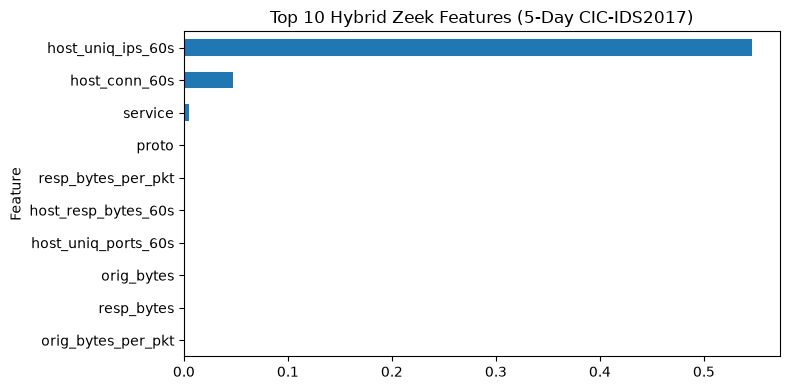

In [4]:
sub = np.random.default_rng(42).choice(te_idx, size=25_000, replace=False)
imp = permutation_importance(
    m_hyb, df.iloc[sub][HYBRID_FEATS], y[sub], n_repeats=3, random_state=42, scoring="f1", n_jobs=-1
)
imp_df = pd.DataFrame({
    "Feature": HYBRID_FEATS,
    "F1 drop when shuffled": imp.importances_mean.round(4),
}).sort_values("F1 drop when shuffled", ascending=False)
display(imp_df.head(12))

imp_df.head(10).iloc[::-1].plot(kind="barh", x="Feature", y="F1 drop when shuffled", figsize=(8, 4), legend=False)
plt.title("Top 10 Hybrid Zeek Features (5-Day CIC-IDS2017)")
plt.tight_layout()
plt.show()

### Key Takeaways
- **Real benign TCP verified:** 5-day Zeek `CIC-IDS2017` has **614k real benign TCP flows** (`ssl`, `http`, `ssh`, `ftp`) with non-zero payloads.
- **Hybrid beats Pure Row-by-Row:** Adding 60s host context cut benign FPR **25×** (`0.75% → 0.03%`) and boosted `Web Attack` recall from `2–10%` to `99–100%`.
- **Audit catch:** `host_uniq_ips_60s` dominated feature importance (`0.546`) because the CIC attacker VM only targeted 1 victim IP. **Next (`10`):** drop IP-fanout shortcuts and stress-test across networks (`CIC-IDS2017` ↔ `UWF`).